# CART: Classification and Regression on Tennis Data

**CART** (Classification And Regression Trees) builds a binary decision tree. At each node it tries every possible yes/no question about the features and keeps the one that makes the two child groups most homogeneous.

| Situation | Target | Impurity measure | A leaf predicts |
|---|---|---|---|
| **Classification** | a category (`Yes` / `No`) | Gini impurity | the most common class |
| **Regression** | a number (hours played) | Mean squared error (MSE) | the average value |

**What this notebook does**

- **Part 1: the CART algorithm from scratch.** One small class that handles both situations.
- **Part 2: the classic Play Tennis dataset (14 rows).** Classification, worked by hand and checked against scikit-learn.
- **Part 3: a synthetic tennis dataset (1,000 rows).** Classification and regression on the same weather features.
- **Part 4: results and conclusions.**

In [1]:
from collections import Counter
from dataclasses import dataclass
from typing import Any, Optional
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import (GridSearchCV, KFold, LeaveOneOut, StratifiedKFold,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

SEED = 42
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

Python 3.10.0 | scikit-learn 1.7.0 | pandas 2.3.1 | numpy 1.26.4


---
# Part 1: CART from scratch

**The two impurity measures**

$$\text{Gini}(S) = 1 - \sum_k p_k^2 \qquad\qquad \text{MSE}(S) = \frac{1}{|S|}\sum_i (y_i - \bar{y})^2$$

**Choosing a split.** A split sends the rows of node $S$ into a left group $L$ and a right group $R$. CART picks the split with the largest drop in impurity:

$$\text{Gain} = \text{Impurity}(S) - \frac{|L|}{|S|}\text{Impurity}(L) - \frac{|R|}{|S|}\text{Impurity}(R)$$

**The questions it can ask.** Trees in CART are always binary:

- Number column: `Humidity <= 70?`, testing the midpoint between each pair of neighbouring values.
- Category column: `Outlook == Sunny?`, testing each category against the rest.

**When it stops.** A node becomes a leaf if it is pure, reaches `max_depth`, or cannot be split without breaking `min_samples_leaf`.

The only difference between the two situations is the impurity function and what a leaf returns.

In [2]:
def gini(y):
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return 1.0 - np.sum(p ** 2)

def mse(y):
    return float(np.mean((y - np.mean(y)) ** 2))


@dataclass
class Node:
    prediction: Any
    n: int
    impurity: float
    feature: Optional[str] = None
    threshold: Any = None
    is_categorical: bool = False
    left: Optional["Node"] = None     # rows where the question is True
    right: Optional["Node"] = None    # rows where the question is False

    @property
    def is_leaf(self):
        return self.left is None


class CART:
    # task = "classification" uses Gini; task = "regression" uses MSE.

    def __init__(self, task="classification", max_depth=None, min_samples_leaf=1):
        if task not in ("classification", "regression"):
            raise ValueError("task must be 'classification' or 'regression'")
        self.task = task
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.impurity = gini if task == "classification" else mse

    def _leaf_value(self, y):
        return Counter(y.tolist()).most_common(1)[0][0] if self.task == "classification" else float(np.mean(y))

    def _candidate_splits(self, X):
        # Yield (feature, threshold, is_categorical, boolean mask) for each possible question.
        for col in X.columns:
            values = X[col].to_numpy()
            if X[col].dtype.kind in "biuf":
                uniques = np.unique(values)
                for threshold in (uniques[:-1] + uniques[1:]) / 2:
                    yield col, float(threshold), False, values <= threshold
            else:
                for category in np.unique(values.astype(str)):
                    yield col, category, True, values.astype(str) == category

    def _best_split(self, X, y):
        parent, n = self.impurity(y), len(y)
        best, best_gain = None, -np.inf
        for col, threshold, is_cat, mask in self._candidate_splits(X):
            n_left = int(mask.sum())
            if n_left < self.min_samples_leaf or n - n_left < self.min_samples_leaf:
                continue
            gain = parent - (n_left / n) * self.impurity(y[mask]) - ((n - n_left) / n) * self.impurity(y[~mask])
            if gain > best_gain + 1e-12:
                best, best_gain = (col, threshold, is_cat, mask), gain
        return best

    def _grow(self, X, y, depth):
        node = Node(self._leaf_value(y), len(y), self.impurity(y))
        if node.impurity < 1e-12 or (self.max_depth is not None and depth >= self.max_depth):
            return node
        split = self._best_split(X, y)
        if split is None:
            return node
        node.feature, node.threshold, node.is_categorical, mask = split
        node.left = self._grow(X[mask], y[mask], depth + 1)
        node.right = self._grow(X[~mask], y[~mask], depth + 1)
        return node

    def fit(self, X, y):
        self.root_ = self._grow(X.reset_index(drop=True), np.asarray(y), 0)
        return self

    def _predict_row(self, row):
        node = self.root_
        while not node.is_leaf:
            value = row[node.feature]
            goes_left = str(value) == node.threshold if node.is_categorical else value <= node.threshold
            node = node.left if goes_left else node.right
        return node.prediction

    def predict(self, X):
        return np.array([self._predict_row(row) for row in X.to_dict("records")])

    def print_tree(self, node=None, indent=""):
        node = node or self.root_
        name = "Gini" if self.task == "classification" else "MSE"
        pred = node.prediction if self.task == "classification" else f"{node.prediction:.2f}"
        if node.is_leaf:
            print(f"{indent}-> predict {pred}  (n={node.n}, {name}={node.impurity:.3f})")
            return
        op = "==" if node.is_categorical else "<="
        thr = node.threshold if node.is_categorical else f"{node.threshold:.2f}"
        print(f"{indent}{node.feature} {op} {thr}?  (n={node.n}, {name}={node.impurity:.3f})")
        print(f"{indent}  True:");  self.print_tree(node.left, indent + "    ")
        print(f"{indent}  False:"); self.print_tree(node.right, indent + "    ")

    def n_leaves(self, node=None):
        node = node or self.root_
        return 1 if node.is_leaf else self.n_leaves(node.left) + self.n_leaves(node.right)

    def depth(self, node=None):
        node = node or self.root_
        return 0 if node.is_leaf else 1 + max(self.depth(node.left), self.depth(node.right))

---
# Part 2: Classic Play Tennis dataset (classification)

These are the 14 days from Tom Mitchell's *Machine Learning* (1997, Table 3.2). The question: **will we play tennis given the weather?**

In [3]:
tennis = pd.DataFrame(
    [["Sunny","Hot","High","Weak","No"],      ["Sunny","Hot","High","Strong","No"],
     ["Overcast","Hot","High","Weak","Yes"],  ["Rain","Mild","High","Weak","Yes"],
     ["Rain","Cool","Normal","Weak","Yes"],   ["Rain","Cool","Normal","Strong","No"],
     ["Overcast","Cool","Normal","Strong","Yes"], ["Sunny","Mild","High","Weak","No"],
     ["Sunny","Cool","Normal","Weak","Yes"],  ["Rain","Mild","Normal","Weak","Yes"],
     ["Sunny","Mild","Normal","Strong","Yes"],["Overcast","Mild","High","Strong","Yes"],
     ["Overcast","Hot","Normal","Weak","Yes"],["Rain","Mild","High","Strong","No"]],
    columns=["Outlook", "Temperature", "Humidity", "Wind", "PlayTennis"],
)
tennis.index = [f"D{i}" for i in range(1, 15)]

X_classic, y_classic = tennis.drop(columns="PlayTennis"), tennis["PlayTennis"]
print("Class counts:", y_classic.value_counts().to_dict())
tennis

Class counts: {'Yes': 9, 'No': 5}


,Outlook,Temperature,Humidity,Wind,PlayTennis
D1,Sunny,Hot,High,Weak,No
D2,Sunny,Hot,High,Strong,No
D3,Overcast,Hot,High,Weak,Yes
D4,Rain,Mild,High,Weak,Yes
D5,Rain,Cool,Normal,Weak,Yes
D6,Rain,Cool,Normal,Strong,No
D7,Overcast,Cool,Normal,Strong,Yes
D8,Sunny,Mild,High,Weak,No
D9,Sunny,Cool,Normal,Weak,Yes
D10,Rain,Mild,Normal,Weak,Yes


## 2.1 Choosing the root split by hand

The full dataset has 9 Yes and 5 No:

$$\text{Gini}(\text{root}) = 1 - \left(\tfrac{9}{14}\right)^2 - \left(\tfrac{5}{14}\right)^2 = 0.459$$

**Worked example: `Outlook == Overcast?`**

- True branch: 4 days, 4 Yes and 0 No, so Gini = 0 (pure).
- False branch: 10 days, 5 Yes and 5 No, so Gini = 1 − 0.5² − 0.5² = 0.500.
- Weighted Gini = (4/14)(0) + (10/14)(0.500) = 0.357.
- Gain = 0.459 − 0.357 = **0.102**.

The next cell repeats this for every possible question.

In [4]:
def split_table(X, y):
    y, parent, rows = np.asarray(y), gini(y), []
    for col in X.columns:
        for category in sorted(X[col].unique()):
            mask = (X[col] == category).to_numpy()
            yes_t, yes_f = (y[mask] == "Yes").sum(), (y[~mask] == "Yes").sum()
            g_t, g_f = gini(y[mask]), gini(y[~mask])
            weighted = mask.mean() * g_t + (~mask).mean() * g_f
            rows.append({"Question": f"{col} == {category}?",
                         "True (Yes/No)": f"{yes_t}/{mask.sum() - yes_t}",
                         "False (Yes/No)": f"{yes_f}/{(~mask).sum() - yes_f}",
                         "Gini True": g_t, "Gini False": g_f,
                         "Weighted Gini": weighted, "Gain": parent - weighted})
    return pd.DataFrame(rows).sort_values("Gain", ascending=False).reset_index(drop=True)

print(f"Root Gini = {gini(y_classic.to_numpy()):.3f}")
split_table(X_classic, y_classic)

Root Gini = 0.459


,Question,True (Yes/No),False (Yes/No),Gini True,Gini False,Weighted Gini,Gain
0,Outlook == Overcast?,4/0,5/5,0.000,0.500,0.357,0.102
1,Humidity == Normal?,6/1,3/4,0.245,0.490,0.367,0.092
2,Humidity == High?,3/4,6/1,0.490,0.245,0.367,0.092
3,Outlook == Sunny?,2/3,7/2,0.480,0.346,0.394,0.066
4,Wind == Weak?,6/2,3/3,0.375,0.500,0.429,0.031
5,Wind == Strong?,3/3,6/2,0.500,0.375,0.429,0.031
6,Temperature == Hot?,2/2,7/3,0.500,0.420,0.443,0.016
7,Temperature == Cool?,3/1,6/4,0.375,0.480,0.450,0.009
8,Outlook == Rain?,3/2,6/3,0.480,0.444,0.457,0.002
9,Temperature == Mild?,4/2,5/3,0.444,0.469,0.458,0.001


`Outlook == Overcast?` has the largest gain, so it becomes the root. Two-valued columns appear twice with the same gain, because `Wind == Weak?` and `Wind == Strong?` are the same split with the branches swapped.

## 2.2 Growing the full tree from scratch

In [5]:
scratch_classic = CART(task="classification").fit(X_classic, y_classic)
scratch_classic.print_tree()
print(f"\nDepth: {scratch_classic.depth()} | Leaves: {scratch_classic.n_leaves()}")
print(f"Training accuracy: {accuracy_score(y_classic, scratch_classic.predict(X_classic)):.3f}")

Outlook == Overcast?  (n=14, Gini=0.459)
  True:
    -> predict Yes  (n=4, Gini=0.000)
  False:
    Humidity == High?  (n=10, Gini=0.500)
      True:
        Outlook == Rain?  (n=5, Gini=0.320)
          True:
            Wind == Strong?  (n=2, Gini=0.500)
              True:
                -> predict No  (n=1, Gini=0.000)
              False:
                -> predict Yes  (n=1, Gini=0.000)
          False:
            -> predict No  (n=3, Gini=0.000)
      False:
        Wind == Strong?  (n=5, Gini=0.320)
          True:
            Outlook == Rain?  (n=2, Gini=0.500)
              True:
                -> predict No  (n=1, Gini=0.000)
              False:
                -> predict Yes  (n=1, Gini=0.000)
          False:
            -> predict Yes  (n=3, Gini=0.000)

Depth: 4 | Leaves: 7
Training accuracy: 1.000


## 2.3 Checking against scikit-learn

scikit-learn's trees need numeric inputs, so the categories are one-hot encoded. A split on `Outlook_Overcast` then asks the same question as `Outlook == Overcast?`.

|--- Outlook_Overcast <= 0.50
|   |--- Humidity_Normal <= 0.50
|   |   |--- Outlook_Rain <= 0.50
|   |   |   |--- class: No
|   |   |--- Outlook_Rain >  0.50
|   |   |   |--- Wind_Strong <= 0.50
|   |   |   |   |--- class: Yes
|   |   |   |--- Wind_Strong >  0.50
|   |   |   |   |--- class: No
|   |--- Humidity_Normal >  0.50
|   |   |--- Wind_Strong <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Wind_Strong >  0.50
|   |   |   |--- Outlook_Sunny <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- Outlook_Sunny >  0.50
|   |   |   |   |--- class: Yes
|--- Outlook_Overcast >  0.50
|   |--- class: Yes

scikit-learn depth: 4 | leaves: 7
Scratch and scikit-learn predictions agree on 14 of 14 days


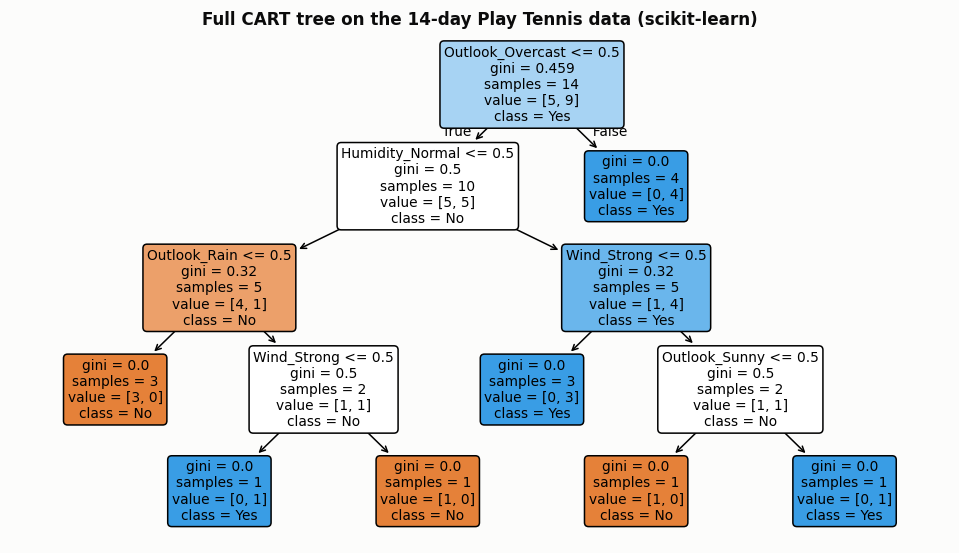

In [6]:
X_classic_ohe = pd.get_dummies(X_classic, dtype=int)
sk_classic = DecisionTreeClassifier(criterion="gini", random_state=SEED).fit(X_classic_ohe, y_classic)

print(export_text(sk_classic, feature_names=list(X_classic_ohe.columns)))
scratch_pred, sk_pred = scratch_classic.predict(X_classic), sk_classic.predict(X_classic_ohe)
print(f"scikit-learn depth: {sk_classic.get_depth()} | leaves: {sk_classic.get_n_leaves()}")
print(f"Scratch and scikit-learn predictions agree on {(scratch_pred == sk_pred).sum()} of {len(y_classic)} days")

fig, ax = plt.subplots(figsize=(11, 6))
plot_tree(sk_classic, feature_names=list(X_classic_ohe.columns), class_names=list(sk_classic.classes_),
          filled=True, rounded=True, impurity=True, fontsize=9, ax=ax)
ax.set_title("Full CART tree on the 14-day Play Tennis data (scikit-learn)")
plt.show()

## 2.4 How well does it generalise?

Training accuracy is 100% because an unpruned tree can memorise 14 rows, so it says little about new days. With so few rows a train/test split would be unreliable, so this uses **leave-one-out cross-validation**: train on 13 days, predict the 14th, and repeat for every day.

In [7]:
scratch_hits = 0
for day in X_classic.index:
    model = CART(task="classification").fit(X_classic.drop(index=day), y_classic.drop(index=day))
    scratch_hits += int(model.predict(X_classic.loc[[day]])[0] == y_classic[day])

majority = y_classic.value_counts(normalize=True).max()

# Many questions tie on gain with so few rows, and the tie-break changes the tree.
# scikit-learn breaks ties using its random seed, so repeat it across 200 seeds.
sk_days = np.array([cross_val_score(DecisionTreeClassifier(random_state=s), X_classic_ohe, y_classic, cv=LeaveOneOut()).sum()
                    for s in range(200)])
sk_seed42 = int(sk_days[SEED])

# The from-scratch tree takes the first tied question, so shuffling the column order changes its tie-breaks.
rng = np.random.default_rng(SEED)
scratch_days = []
for _ in range(60):
    shuffled = X_classic[list(rng.permutation(X_classic.columns))]
    hits = sum(int(CART().fit(shuffled.drop(index=d), y_classic.drop(index=d)).predict(shuffled.loc[[d]])[0] == y_classic[d])
               for d in shuffled.index)
    scratch_days.append(hits)
scratch_days = np.array(scratch_days)

display(pd.DataFrame({
    "Model": ["Always predict the majority class (Yes)", "CART from scratch, original column order", "CART from scratch, 60 shuffled column orders",
              "CART scikit-learn, seed 42", "CART scikit-learn, 200 seeds"],
    "Mean days correct (of 14)": [majority * 14, scratch_hits, scratch_days.mean(), sk_seed42, sk_days.mean()],
    "Range of days correct": ["-", "-", f"{scratch_days.min():.0f} to {scratch_days.max():.0f}", "-", f"{sk_days.min():.0f} to {sk_days.max():.0f}"],
    "Leave-one-out accuracy": [majority, scratch_hits / 14, scratch_days.mean() / 14, sk_seed42 / 14, sk_days.mean() / 14],
}))

new_days = pd.DataFrame([["Sunny", "Cool", "High", "Strong"], ["Overcast", "Hot", "High", "Weak"], ["Rain", "Mild", "Normal", "Weak"]],
                        columns=X_classic.columns)
new_ohe = pd.get_dummies(new_days, dtype=int).reindex(columns=X_classic_ohe.columns, fill_value=0)
new_days.assign(Scratch=scratch_classic.predict(new_days), ScikitLearn=sk_classic.predict(new_ohe))

,Model,Mean days correct (of 14),Range of days correct,Leave-one-out accuracy
0,Always predict the majority class (Yes),9.000,-,0.643
1,"CART from scratch, original column order",7.000,-,0.500
2,"CART from scratch, 60 shuffled column orders",8.100,7 to 9,0.579
3,"CART scikit-learn, seed 42",9.000,-,0.643
4,"CART scikit-learn, 200 seeds",8.340,6 to 9,0.596


,Outlook,Temperature,Humidity,Wind,Scratch,ScikitLearn
0,Sunny,Cool,High,Strong,No,No
1,Overcast,Hot,High,Weak,Yes,Yes
2,Rain,Mild,Normal,Weak,Yes,Yes


**What this shows**

- **The from-scratch tree is correct on this data.** Both versions start with `Outlook == Overcast?`, then split on humidity, and have the same depth (4) and leaf count (7). They agree on all 14 training days and on the three new days.
- **The tree does not beat the simple baseline.** Always answering Yes gets 9 of 14 days right. CART averages 8.34 with scikit-learn and 8.10 from scratch, and neither version exceeded 9 in any of these runs.
- **Tie-breaks change the result.** When several questions have the same gain, the from-scratch tree takes the first and scikit-learn chooses using its seed. Accuracy therefore moves between 6 and 9 days with no change to the data. Seed 42 happens to reach 9, which is why the averages are reported as well.

This dataset is good for following the algorithm by hand, but 14 rows are too few to measure how well a tree predicts. Part 3 addresses that with more data.

---
# Part 3: Synthetic tennis dataset (classification and regression)

The classic data has only 14 rows and no numeric target, so it cannot show regression or a real train/test evaluation. This synthetic dataset has 1,000 days of a tennis club's records, with **one set of weather features and two targets**:

| Column | Type | Role |
|---|---|---|
| `Outlook` | Sunny / Overcast / Rain | feature |
| `Temperature_C` | number | feature |
| `Humidity_pct` | number | feature |
| `Wind_kmh` | number | feature |
| `Weekend` | 0 / 1 | feature |
| `PlayTennis` | Yes / No | **classification target** |
| `HoursPlayed` | number | **regression target** |

**The rules used to generate the data**

*`PlayTennis`*, following the pattern of the classic dataset, with 10% of labels flipped at random as noise:
- Overcast: Yes
- Sunny: Yes when humidity is at most 70%
- Rain: Yes when wind is at most 20 km/h

*`HoursPlayed`*, with random noise (standard deviation 0.35 hours) added:

$$\text{Hours} = 3.5 + 1.2\,\text{Weekend} + 0.8\,\text{Overcast} - 0.6\,\text{Rain} - 0.008\,(\text{Temp}-24)^2 - 0.025\,\max(\text{Humidity}-60,\,0) - 0.03\,\text{Wind}$$

Because the true rules are known, the trees can be checked against them. Temperature and Weekend have **no effect** on `PlayTennis`, so a good classifier should ignore them.

Neither target is used as a feature for the other.

In [8]:
def make_synthetic_tennis(n=1000, label_noise=0.10, hours_noise=0.35, seed=SEED):
    rng = np.random.default_rng(seed)
    outlook = rng.choice(["Sunny", "Overcast", "Rain"], size=n, p=[0.36, 0.28, 0.36])

    temp_mean = pd.Series(outlook).map({"Sunny": 27, "Overcast": 22, "Rain": 18}).to_numpy()
    temp_sd   = pd.Series(outlook).map({"Sunny": 5, "Overcast": 4, "Rain": 4}).to_numpy()
    hum_mean  = pd.Series(outlook).map({"Sunny": 62, "Overcast": 68, "Rain": 80}).to_numpy()
    hum_sd    = pd.Series(outlook).map({"Sunny": 14, "Overcast": 10, "Rain": 10}).to_numpy()

    temperature = np.clip(rng.normal(temp_mean, temp_sd), 8, 38).round(1)
    humidity    = np.clip(rng.normal(hum_mean, hum_sd), 25, 100).round(1)
    wind        = np.clip(rng.normal(18, 8, n), 0, 50).round(1)
    weekend     = rng.binomial(1, 2 / 7, n)

    is_sunny, is_overcast, is_rain = outlook == "Sunny", outlook == "Overcast", outlook == "Rain"

    # Classification target: true rule, then flip a share of labels
    true_rule = is_overcast | (is_sunny & (humidity <= 70)) | (is_rain & (wind <= 20))
    flip = rng.random(n) < label_noise
    play = np.where(true_rule ^ flip, "Yes", "No")

    # Regression target: non-linear formula plus noise
    true_hours = (3.5 + 1.2 * weekend + 0.8 * is_overcast - 0.6 * is_rain
                  - 0.008 * (temperature - 24) ** 2
                  - 0.025 * np.maximum(humidity - 60, 0)
                  - 0.03 * wind)
    hours = np.clip(true_hours + rng.normal(0, hours_noise, n), 0, None).round(2)

    return pd.DataFrame({"Outlook": outlook, "Temperature_C": temperature, "Humidity_pct": humidity,
                         "Wind_kmh": wind, "Weekend": weekend, "PlayTennis": play, "HoursPlayed": hours})

synthetic = make_synthetic_tennis()
print("Shape:", synthetic.shape, "| Missing values:", int(synthetic.isna().sum().sum()))
print("PlayTennis:", synthetic["PlayTennis"].value_counts().to_dict())
display(synthetic.head())
synthetic.describe()

Shape: (1000, 7) | Missing values: 0
PlayTennis: {'Yes': 696, 'No': 304}


,Outlook,Temperature_C,Humidity_pct,Wind_kmh,Weekend,PlayTennis,HoursPlayed
0,Rain,15.000,79.100,12.500,0,Yes,1.560
1,Overcast,25.700,63.700,34.300,0,Yes,3.050
2,Rain,18.100,88.000,17.700,0,Yes,1.310
3,Rain,16.900,77.600,26.200,0,No,1.870
4,Sunny,26.500,57.700,17.600,1,Yes,5.070


,Temperature_C,Humidity_pct,Wind_kmh,Weekend,HoursPlayed
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,22.013,70.263,18.146,0.260,2.678
std,5.711,14.247,7.846,0.439,1.106
min,8.000,25.000,0.000,0.000,0.000
25%,17.900,61.600,12.600,0.000,1.907
50%,21.400,71.750,18.050,0.000,2.740
75%,26.100,80.300,23.300,1.000,3.422
max,38.000,100.000,42.700,1.000,5.800


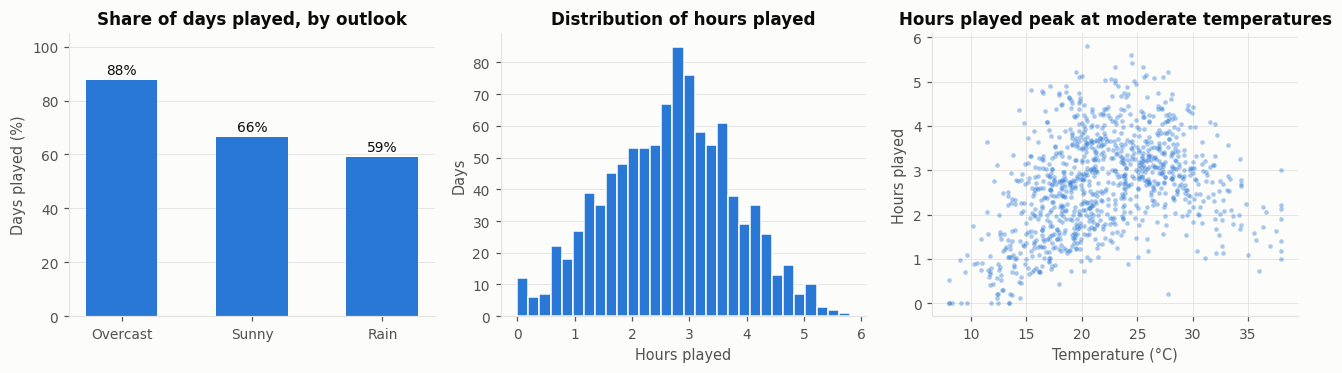

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

rate = synthetic.assign(Yes=synthetic["PlayTennis"].eq("Yes")).groupby("Outlook")["Yes"].mean().loc[["Overcast", "Sunny", "Rain"]] * 100
bars = axes[0].bar(rate.index, rate.values, color=BLUE, width=0.55)
axes[0].bar_label(bars, fmt="%.0f%%", color=INK, fontsize=9, padding=2)
axes[0].set(title="Share of days played, by outlook", ylabel="Days played (%)", ylim=(0, 105))
axes[0].grid(axis="x", visible=False)

axes[1].hist(synthetic["HoursPlayed"], bins=30, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[1].set(title="Distribution of hours played", xlabel="Hours played", ylabel="Days")
axes[1].grid(axis="x", visible=False)

axes[2].scatter(synthetic["Temperature_C"], synthetic["HoursPlayed"], s=9, alpha=0.4, color=BLUE, linewidths=0)
axes[2].set(title="Hours played peak at moderate temperatures", xlabel="Temperature (°C)", ylabel="Hours played")

fig.tight_layout()
plt.show()

## 3.1 Train/test split and encoding

Both situations share one 80/20 split, stratified on `PlayTennis`. The test set is used **only for the final evaluation**; all tuning uses cross-validation on the training set.

In [10]:
FEATURES = ["Outlook", "Temperature_C", "Humidity_pct", "Wind_kmh", "Weekend"]
X_raw = synthetic[FEATURES]
X_ohe = pd.get_dummies(X_raw, columns=["Outlook"], dtype=int)
y_clf, y_reg = synthetic["PlayTennis"], synthetic["HoursPlayed"]

train_idx, test_idx = train_test_split(synthetic.index, test_size=0.2, random_state=SEED, stratify=y_clf)

X_train, X_test = X_ohe.loc[train_idx], X_ohe.loc[test_idx]
X_train_raw, X_test_raw = X_raw.loc[train_idx], X_raw.loc[test_idx]
y_clf_train, y_clf_test = y_clf.loc[train_idx], y_clf.loc[test_idx]
y_reg_train, y_reg_test = y_reg.loc[train_idx], y_reg.loc[test_idx]

print(f"Train: {len(train_idx)} rows | Test: {len(test_idx)} rows")
print("Encoded features:", list(X_ohe.columns))

Train: 800 rows | Test: 200 rows
Encoded features: ['Temperature_C', 'Humidity_pct', 'Wind_kmh', 'Weekend', 'Outlook_Overcast', 'Outlook_Rain', 'Outlook_Sunny']


## 3.2 Tree depth and overfitting

Before tuning, this checks how depth changes performance. Each model is scored on its own training data and with 5-fold cross-validation.

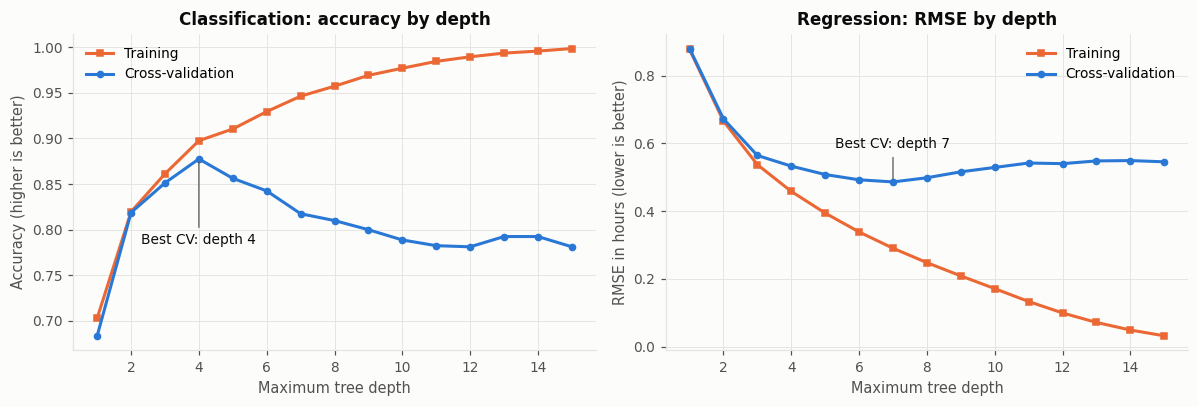

Classification: best CV accuracy 0.878 at depth 4; at depth 15, train 0.998 and CV 0.781
Regression: best CV RMSE 0.486 at depth 7; at depth 15, train 0.032 and CV 0.546


In [11]:
depths = list(range(1, 16))
clf_cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
reg_cv = KFold(5, shuffle=True, random_state=SEED)

clf_train, clf_valid, reg_train, reg_valid = [], [], [], []
for d in depths:
    c = cross_validate(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_clf_train,
                       cv=clf_cv, scoring="accuracy", return_train_score=True)
    r = cross_validate(DecisionTreeRegressor(max_depth=d, random_state=SEED), X_train, y_reg_train,
                       cv=reg_cv, scoring="neg_root_mean_squared_error", return_train_score=True)
    clf_train.append(c["train_score"].mean()); clf_valid.append(c["test_score"].mean())
    reg_train.append(-r["train_score"].mean()); reg_valid.append(-r["test_score"].mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
series = [(axes[0], clf_train, clf_valid, "Classification: accuracy by depth", "Accuracy (higher is better)", np.argmax(clf_valid)),
          (axes[1], reg_train, reg_valid, "Regression: RMSE by depth", "RMSE in hours (lower is better)", np.argmin(reg_valid))]
for ax, tr, va, title, ylabel, best in series:
    ax.plot(depths, tr, color=ORANGE, marker="s", ms=4, label="Training")
    ax.plot(depths, va, color=BLUE, marker="o", ms=4, label="Cross-validation")
    ax.annotate(f"Best CV: depth {depths[best]}", (depths[best], va[best]), xytext=(0, -56 if ax is axes[0] else 22),
                textcoords="offset points", ha="center", fontsize=9, color=INK,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    ax.set(title=title, xlabel="Maximum tree depth", ylabel=ylabel)
    ax.legend()
fig.tight_layout()
plt.show()
print(f"Classification: best CV accuracy {max(clf_valid):.3f} at depth {depths[int(np.argmax(clf_valid))]}; at depth 15, train {clf_train[-1]:.3f} and CV {clf_valid[-1]:.3f}")
print(f"Regression: best CV RMSE {min(reg_valid):.3f} at depth {depths[int(np.argmin(reg_valid))]}; at depth 15, train {reg_train[-1]:.3f} and CV {reg_valid[-1]:.3f}")

**What this shows.** In both situations the training score keeps improving as the tree deepens, while the cross-validation score reaches a best point and then gets worse. That gap is overfitting.

| Situation | Best CV score | Best depth | CV score at depth 15 | Training score at depth 15 |
|---|---|---|---|---|
| Classification (accuracy) | 0.878 | 4 | 0.781 | 0.998 |
| Regression (RMSE, hours) | 0.486 | 7 | 0.546 | 0.032 |

Regression benefits from a deeper tree here because it needs more steps to follow a continuous target.

## 3.3 Situation 1: Classification, predicting `PlayTennis`

The grid search tunes three settings by 5-fold cross-validation on the training set:

- `max_depth`: how deep the tree may grow.
- `min_samples_leaf`: the smallest allowed leaf.
- `ccp_alpha`: cost-complexity pruning, the pruning method from the original CART algorithm. Higher values remove more branches.

In [12]:
grid_clf = GridSearchCV(
    DecisionTreeClassifier(criterion="gini", random_state=SEED),
    {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20], "ccp_alpha": [0.0, 0.001, 0.005, 0.01]},
    cv=clf_cv, scoring="accuracy", n_jobs=-1,
).fit(X_train, y_clf_train)
best_clf = grid_clf.best_estimator_
print("Best settings:", grid_clf.best_params_)
print(f"Best CV accuracy: {grid_clf.best_score_:.3f} | depth {best_clf.get_depth()} | leaves {best_clf.get_n_leaves()}")

# Same depth and leaf settings for the from-scratch tree, which has no pruning step
scratch_clf = CART("classification", max_depth=best_clf.get_depth(),
                   min_samples_leaf=grid_clf.best_params_["min_samples_leaf"]).fit(X_train_raw, y_clf_train)

models_clf = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent").fit(X_train, y_clf_train),
    "Unpruned CART": DecisionTreeClassifier(random_state=SEED).fit(X_train, y_clf_train),
    "Tuned CART": best_clf,
}
rows = []
for name, m in models_clf.items():
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    rows.append({"Model": name, "Train accuracy": accuracy_score(y_clf_train, p_tr), "Test accuracy": accuracy_score(y_clf_test, p_te),
                 "Test F1 (Yes)": f1_score(y_clf_test, p_te, pos_label="Yes"), "Leaves": getattr(m, "get_n_leaves", lambda: 1)()})
p_tr, p_te = scratch_clf.predict(X_train_raw), scratch_clf.predict(X_test_raw)
rows.append({"Model": "CART from scratch", "Train accuracy": accuracy_score(y_clf_train, p_tr), "Test accuracy": accuracy_score(y_clf_test, p_te),
             "Test F1 (Yes)": f1_score(y_clf_test, p_te, pos_label="Yes"), "Leaves": scratch_clf.n_leaves()})

# The generating rule itself, without the label noise, is the best anything can realistically do
te = X_raw.loc[test_idx]
rule = (te["Outlook"].eq("Overcast") | (te["Outlook"].eq("Sunny") & te["Humidity_pct"].le(70)) | (te["Outlook"].eq("Rain") & te["Wind_kmh"].le(20)))
p_rule = np.where(rule, "Yes", "No")
rows.append({"Model": "True generating rule (reference)", "Train accuracy": np.nan, "Test accuracy": accuracy_score(y_clf_test, p_rule),
             "Test F1 (Yes)": f1_score(y_clf_test, p_rule, pos_label="Yes"), "Leaves": np.nan})
results_clf = pd.DataFrame(rows)
results_clf

Best settings: {'ccp_alpha': 0.0, 'max_depth': 4, 'min_samples_leaf': 10}
Best CV accuracy: 0.891 | depth 4 | leaves 16


,Model,Train accuracy,Test accuracy,Test F1 (Yes),Leaves
0,Baseline (majority class),0.696,0.695,0.820,1.000
1,Unpruned CART,1.000,0.795,0.851,150.000
2,Tuned CART,0.894,0.895,0.928,16.000
3,CART from scratch,0.894,0.895,0.928,16.000
4,True generating rule (reference),NaN,0.900,0.931,NaN


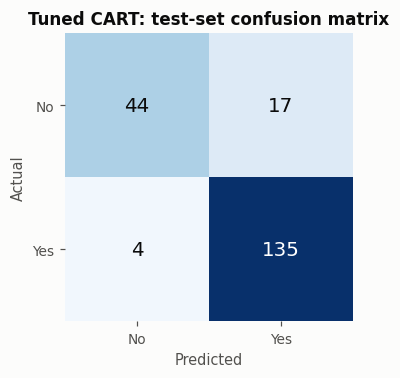

Correct: 179 of 200 | False Yes: 17 | False No: 4


In [13]:
pred_clf = best_clf.predict(X_test)
labels = ["No", "Yes"]
cm = confusion_matrix(y_clf_test, pred_clf, labels=labels)

fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(cm, cmap="Blues", vmin=0)
ax.grid(False)
ax.set_xticks([0, 1], labels); ax.set_yticks([0, 1], labels)
ax.set(xlabel="Predicted", ylabel="Actual", title="Tuned CART: test-set confusion matrix")
for s in ax.spines.values(): s.set_visible(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() * 0.55 else INK)
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Correct: {tp + tn} of {cm.sum()} | False Yes: {fp} | False No: {fn}")

|--- Wind_kmh <= 20.05
|   |--- Outlook_Sunny <= 0.50
|   |   |--- Temperature_C <= 23.10
|   |   |   |--- Wind_kmh <= 4.75
|   |   |   |   |--- class: Yes
|   |   |   |--- Wind_kmh >  4.75
|   |   |   |   |--- class: Yes
|   |   |--- Temperature_C >  23.10
|   |   |   |--- Humidity_pct <= 67.00
|   |   |   |   |--- class: Yes
|   |   |   |--- Humidity_pct >  67.00
|   |   |   |   |--- class: Yes
|   |--- Outlook_Sunny >  0.50
|   |   |--- Humidity_pct <= 70.05
|   |   |   |--- Humidity_pct <= 36.75
|   |   |   |   |--- class: Yes
|   |   |   |--- Humidity_pct >  36.75
|   |   |   |   |--- class: Yes
|   |   |--- Humidity_pct >  70.05
|   |   |   |--- Temperature_C <= 30.35
|   |   |   |   |--- class: No
|   |   |   |--- Temperature_C >  30.35
|   |   |   |   |--- class: No
|--- Wind_kmh >  20.05
|   |--- Outlook_Rain <= 0.50
|   |   |--- Humidity_pct <= 72.25
|   |   |   |--- Wind_kmh <= 22.75
|   |   |   |   |--- class: Yes
|   |   |   |--- Wind_kmh >  22.75
|   |   |   |   |--- clas

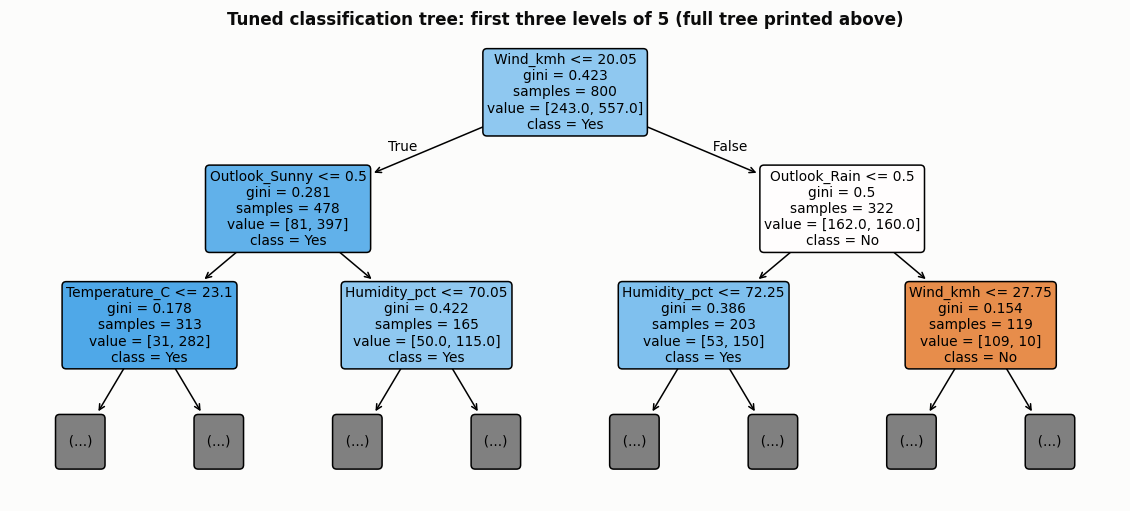

In [14]:
print(export_text(best_clf, feature_names=list(X_train.columns), show_weights=False))

fig, ax = plt.subplots(figsize=(13, 5.5))
plot_tree(best_clf, feature_names=list(X_train.columns), class_names=list(best_clf.classes_), max_depth=2,
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title(f"Tuned classification tree: first three levels of {best_clf.get_depth() + 1} (full tree printed above)")
plt.show()

**What this shows**

- **The tuned tree is close to the best possible.** Test accuracy is 0.895, against 0.695 for the baseline and 0.900 for the true generating rule. The rule itself gets 20 of the 200 test days wrong because of the label noise, and the tree gets 21 wrong.
- **Pruning matters.** The unpruned tree grows 150 leaves and scores 1.000 on training data but only 0.795 on the test set, because it memorises the noisy labels. The tuned tree has 16 leaves.
- **The tree found the hidden thresholds.** It splits at `Wind_kmh <= 20.05` and `Humidity_pct <= 70.05`; the true values are 20 and 70.
- **The root differs from the written rule, but the logic is the same.** The rule was written starting with outlook, while the tree starts with wind, because CART only picks the best split at each step. Below that, Sunny days depend on humidity and windy Rain days become No, as the rule says.
- **Temperature does not change any prediction.** The tree does split on it twice, but both branches of each split predict the same class. Those splits lower Gini without changing the answer. `Weekend` is not used at all.
- **The from-scratch tree matches.** With the same depth and leaf settings, it gives the same accuracy, F1 and leaf count as scikit-learn.

## 3.4 Situation 2: Regression, predicting `HoursPlayed`

This uses the same features and split, with MSE in place of Gini. Each leaf now predicts the **average** hours of the training rows that reach it, which gives a step-shaped prediction rather than a smooth curve. The chart below shows this using temperature alone.

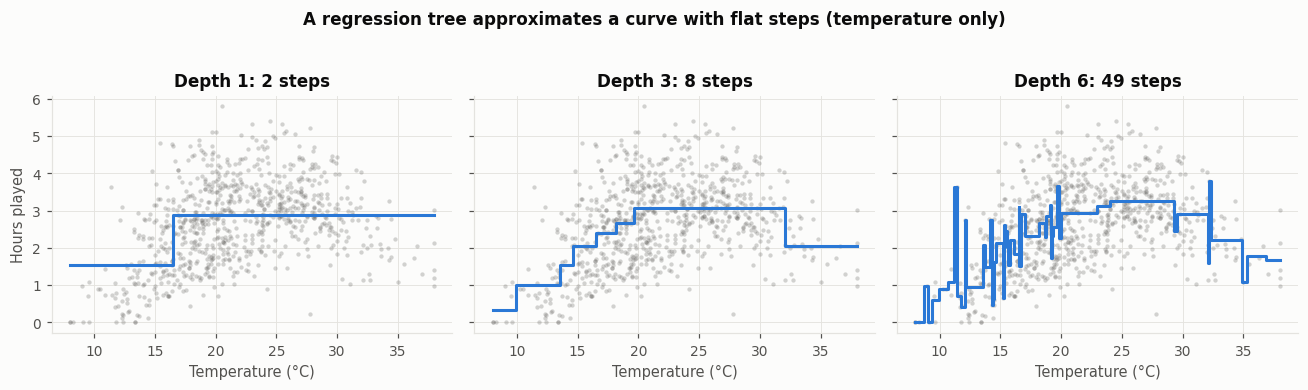

In [15]:
grid_x = pd.DataFrame({"Temperature_C": np.linspace(X_train["Temperature_C"].min(), X_train["Temperature_C"].max(), 400)})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, d in zip(axes, [1, 3, 6]):
    m = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train[["Temperature_C"]], y_reg_train)
    ax.scatter(X_train["Temperature_C"], y_reg_train, s=8, alpha=0.25, color=MUTED, linewidths=0)
    ax.plot(grid_x["Temperature_C"], m.predict(grid_x), color=BLUE, drawstyle="steps-post")
    ax.set(title=f"Depth {d}: {m.get_n_leaves()} steps", xlabel="Temperature (°C)")
axes[0].set_ylabel("Hours played")
fig.suptitle("A regression tree approximates a curve with flat steps (temperature only)", fontsize=11, fontweight="bold", color=INK, y=1.03)
fig.tight_layout()
plt.show()

In [16]:
grid_reg = GridSearchCV(
    DecisionTreeRegressor(criterion="squared_error", random_state=SEED),
    {"max_depth": [2, 3, 4, 5, 6, 8, 10, 12, None], "min_samples_leaf": [1, 5, 10, 20], "ccp_alpha": [0.0, 0.001, 0.005, 0.01, 0.02]},
    cv=reg_cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_reg_train)
best_reg = grid_reg.best_estimator_
print("Best settings:", grid_reg.best_params_)
print(f"Best CV RMSE: {-grid_reg.best_score_:.3f} hours | depth {best_reg.get_depth()} | leaves {best_reg.get_n_leaves()}")

scratch_reg = CART("regression", max_depth=best_reg.get_depth(),
                   min_samples_leaf=grid_reg.best_params_["min_samples_leaf"]).fit(X_train_raw, y_reg_train)

def reg_row(name, y_tr, p_tr, y_te, p_te, leaves):
    return {"Model": name, "Train RMSE": np.sqrt(mean_squared_error(y_tr, p_tr)), "Test RMSE": np.sqrt(mean_squared_error(y_te, p_te)),
            "Test MAE": mean_absolute_error(y_te, p_te), "Test R²": r2_score(y_te, p_te), "Leaves": leaves}

models_reg = {
    "Baseline (mean)": DummyRegressor(strategy="mean").fit(X_train, y_reg_train),
    "Unpruned CART": DecisionTreeRegressor(random_state=SEED).fit(X_train, y_reg_train),
    "Tuned CART": best_reg,
}
rows = [reg_row(n, y_reg_train, m.predict(X_train), y_reg_test, m.predict(X_test), getattr(m, "get_n_leaves", lambda: 1)()) for n, m in models_reg.items()]
rows.append(reg_row("CART from scratch", y_reg_train, scratch_reg.predict(X_train_raw), y_reg_test, scratch_reg.predict(X_test_raw), scratch_reg.n_leaves()))

results_reg = pd.DataFrame(rows)
print("The noise added to the data has a standard deviation of 0.35 hours, so no model should beat a test RMSE of about 0.35.")
results_reg

Best settings: {'ccp_alpha': 0.0, 'max_depth': 6, 'min_samples_leaf': 5}
Best CV RMSE: 0.484 hours | depth 6 | leaves 51


The noise added to the data has a standard deviation of 0.35 hours, so no model should beat a test RMSE of about 0.35.


,Model,Train RMSE,Test RMSE,Test MAE,Test R²,Leaves
0,Baseline (mean),1.118,1.053,0.847,-0.005,1
1,Unpruned CART,0.000,0.574,0.468,0.701,786
2,Tuned CART,0.367,0.468,0.377,0.801,51
3,CART from scratch,0.367,0.468,0.377,0.801,51


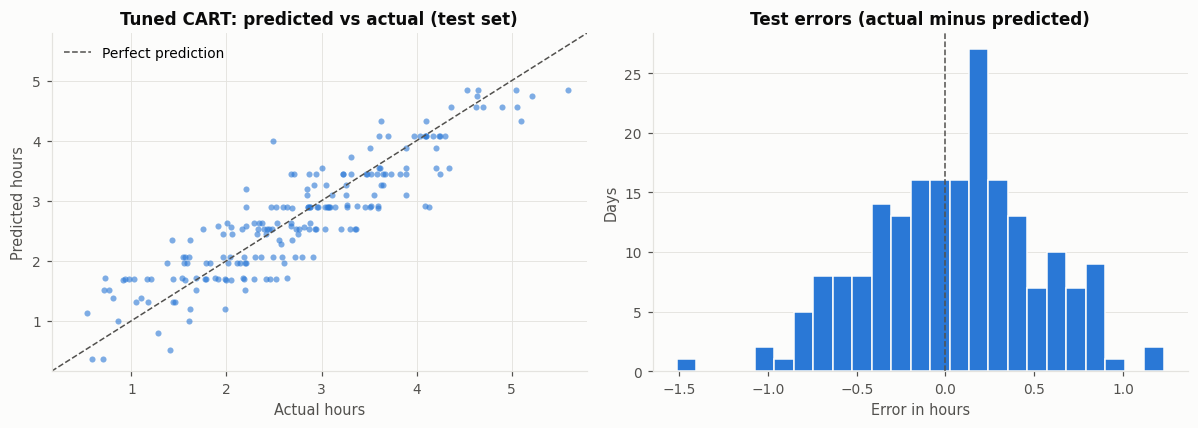

Distinct predicted values on the test set: 42 (one per leaf reached)
Mean error: +0.045 hours


In [17]:
pred_reg = best_reg.predict(X_test)
residuals = y_reg_test - pred_reg

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lims = [min(y_reg_test.min(), pred_reg.min()) - 0.2, max(y_reg_test.max(), pred_reg.max()) + 0.2]
axes[0].plot(lims, lims, color=MUTED, lw=1, ls="--", label="Perfect prediction")
axes[0].legend(loc="upper left")
axes[0].scatter(y_reg_test, pred_reg, s=16, alpha=0.6, color=BLUE, linewidths=0)
axes[0].set(title="Tuned CART: predicted vs actual (test set)", xlabel="Actual hours", ylabel="Predicted hours", xlim=lims, ylim=lims)

axes[1].hist(residuals, bins=25, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[1].axvline(0, color=MUTED, lw=1, ls="--")
axes[1].set(title="Test errors (actual minus predicted)", xlabel="Error in hours", ylabel="Days")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
print(f"Distinct predicted values on the test set: {len(np.unique(pred_reg))} (one per leaf reached)")
print(f"Mean error: {residuals.mean():+.3f} hours")

First three levels of the tuned regression tree:

|--- Outlook_Rain <= 0.50
|   |--- Weekend <= 0.50
|   |   |--- Outlook_Overcast <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- Outlook_Overcast >  0.50
|   |   |   |--- truncated branch of depth 4
|   |--- Weekend >  0.50
|   |   |--- Outlook_Overcast <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- Outlook_Overcast >  0.50
|   |   |   |--- truncated branch of depth 4
|--- Outlook_Rain >  0.50
|   |--- Weekend <= 0.50
|   |   |--- Temperature_C <= 15.30
|   |   |   |--- truncated branch of depth 4
|   |   |--- Temperature_C >  15.30
|   |   |   |--- truncated branch of depth 4
|   |--- Weekend >  0.50
|   |   |--- Humidity_pct <= 78.95
|   |   |   |--- truncated branch of depth 3
|   |   |--- Humidity_pct >  78.95
|   |   |   |--- truncated branch of depth 4



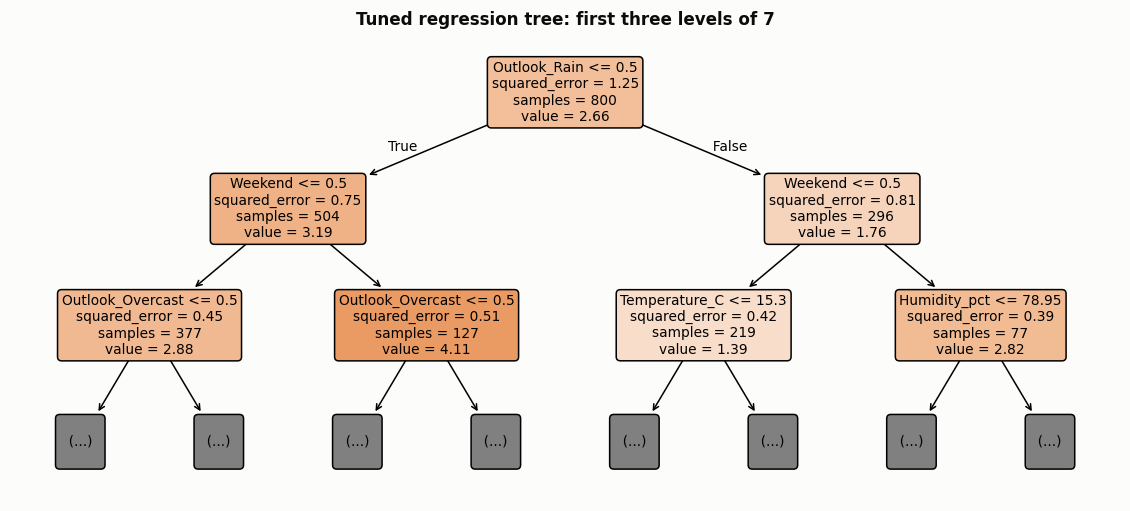

In [18]:
print("First three levels of the tuned regression tree:\n")
print(export_text(best_reg, feature_names=list(X_train.columns), max_depth=2, decimals=2))

fig, ax = plt.subplots(figsize=(13, 5.5))
plot_tree(best_reg, feature_names=list(X_train.columns), max_depth=2, filled=True, rounded=True, fontsize=9, precision=2, ax=ax)
ax.set_title(f"Tuned regression tree: first three levels of {best_reg.get_depth() + 1}")
plt.show()

**What this shows**

- **The tuned tree explains most of the variation.** Test R² is 0.801 and RMSE is 0.468 hours, against 1.053 for the baseline that always predicts the mean. The average error (MAE) is 0.377 hours, about 23 minutes.
- **It does not reach the noise level of about 0.35 hours.** The rest of the gap comes largely from using flat steps to follow smooth effects such as the temperature curve.
- **Pruning matters here too.** The unpruned tree has 786 leaves, one for nearly every training row. Its training RMSE is 0.000, but its test RMSE is 0.574, worse than the tuned tree's 0.468 with 51 leaves.
- **Predictions come in fixed levels.** The horizontal bands in the predicted vs actual chart are leaves: the test set receives only 42 distinct predictions. A regression tree also cannot predict above or below the averages it saw in training.
- **The from-scratch tree matches.** With the same depth and leaf settings, its RMSE, MAE, R² and leaf count equal scikit-learn's to three decimals.

## 3.5 Comparing feature importance

A feature's importance is its share of the total impurity reduction across the tree. The two targets were generated by different rules, so the same features should matter differently.

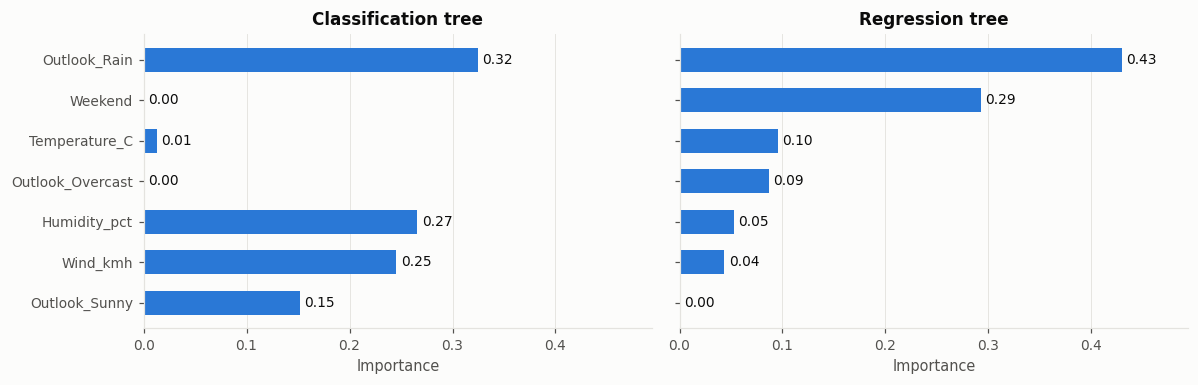

,Classification,Regression
Outlook_Rain,0.324,0.429
Humidity_pct,0.266,0.053
Wind_kmh,0.245,0.043
Outlook_Sunny,0.152,0.000
Temperature_C,0.013,0.095
Outlook_Overcast,0.000,0.087
Weekend,0.000,0.293


In [19]:
importance = pd.DataFrame({"Classification": best_clf.feature_importances_, "Regression": best_reg.feature_importances_},
                          index=X_train.columns).sort_values("Regression")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col in zip(axes, importance.columns):
    bars = ax.barh(importance.index, importance[col], color=BLUE, height=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=3, color=INK, fontsize=9)
    ax.set(title=f"{col} tree", xlabel="Importance", xlim=(0, max(importance.max()) * 1.15))
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()
importance.sort_values("Classification", ascending=False)

## 3.6 Predicting new days

Both tuned trees score the same new days, and each value is compared with what the generating rules say.

In [20]:
new_days = pd.DataFrame(
    [["Overcast", 24.0, 65.0, 10.0, 1],
     ["Sunny",    30.0, 85.0, 12.0, 0],
     ["Sunny",    25.0, 50.0,  8.0, 1],
     ["Rain",     16.0, 85.0, 30.0, 0],
     ["Rain",     20.0, 70.0, 10.0, 1]],
    columns=FEATURES)

new_ohe = pd.get_dummies(new_days, columns=["Outlook"], dtype=int).reindex(columns=X_train.columns, fill_value=0)

is_s, is_o, is_r = new_days["Outlook"].eq("Sunny"), new_days["Outlook"].eq("Overcast"), new_days["Outlook"].eq("Rain")
rule_play = np.where(is_o | (is_s & new_days["Humidity_pct"].le(70)) | (is_r & new_days["Wind_kmh"].le(20)), "Yes", "No")
rule_hours = (3.5 + 1.2 * new_days["Weekend"] + 0.8 * is_o - 0.6 * is_r - 0.008 * (new_days["Temperature_C"] - 24) ** 2
              - 0.025 * (new_days["Humidity_pct"] - 60).clip(lower=0) - 0.03 * new_days["Wind_kmh"])

new_days.assign(**{"Rule: play": rule_play, "Tree: play": best_clf.predict(new_ohe),
                   "Rule: hours": rule_hours.round(2), "Tree: hours": best_reg.predict(new_ohe).round(2)})

,Outlook,Temperature_C,Humidity_pct,Wind_kmh,Weekend,Rule: play,Tree: play,Rule: hours,Tree: hours
0,Overcast,24.000,65.000,10.000,1,Yes,Yes,5.080,4.840
1,Sunny,30.000,85.000,12.000,0,No,No,2.230,2.620
2,Sunny,25.000,50.000,8.000,1,Yes,Yes,4.450,4.080
3,Rain,16.000,85.000,30.000,0,No,No,0.860,1.190
4,Rain,20.000,70.000,10.000,1,Yes,Yes,3.420,3.370


---
# Part 4: Results and conclusions

In [21]:
summary = pd.DataFrame([
    {"Dataset": "Classic tennis (14 rows)", "Situation": "Classification", "Metric": "Leave-one-out accuracy",
     "Baseline": majority, "CART": sk_days.mean() / 14},
    {"Dataset": "Synthetic tennis (1,000 rows)", "Situation": "Classification", "Metric": "Test accuracy",
     "Baseline": results_clf.loc[0, "Test accuracy"], "CART": results_clf.loc[2, "Test accuracy"]},
    {"Dataset": "Synthetic tennis (1,000 rows)", "Situation": "Regression", "Metric": "Test RMSE (hours)",
     "Baseline": results_reg.loc[0, "Test RMSE"], "CART": results_reg.loc[2, "Test RMSE"]},
    {"Dataset": "Synthetic tennis (1,000 rows)", "Situation": "Regression", "Metric": "Test R²",
     "Baseline": results_reg.loc[0, "Test R²"], "CART": results_reg.loc[2, "Test R²"]},
])
summary

,Dataset,Situation,Metric,Baseline,CART
0,Classic tennis (14 rows),Classification,Leave-one-out accuracy,0.643,0.596
1,"Synthetic tennis (1,000 rows)",Classification,Test accuracy,0.695,0.895
2,"Synthetic tennis (1,000 rows)",Regression,Test RMSE (hours),1.053,0.468
3,"Synthetic tennis (1,000 rows)",Regression,Test R²,-0.005,0.801


**1. One algorithm covers both situations.** The same from-scratch class handled classification and regression by changing only the impurity measure (Gini or MSE) and the leaf value (most common class or average). On both datasets, its fitted trees gave the same results as scikit-learn's.

**2. The classic dataset teaches the method but cannot measure it.** The hand calculation gives `Outlook == Overcast?` as the root with a gain of 0.102, matching both trees. On unseen days, CART did not beat always answering Yes.

**3. Classification on synthetic data: 0.895 test accuracy.** That compares with 0.695 for the baseline and 0.900 for the true rule, and the 5-fold cross-validation score of 0.891 supports it. The tree also recovered the wind and humidity thresholds.

**4. Regression on synthetic data: R² of 0.801.** Test RMSE was 0.468 hours against a baseline of 1.053, and the cross-validation RMSE of 0.484 supports it.

**5. Controlling tree size was the most important modelling choice.**

| Situation | Metric | Unpruned tree | Tuned tree |
|---|---|---|---|
| Classification | Test accuracy | 0.795 (150 leaves) | 0.895 (16 leaves) |
| Regression | Test RMSE (hours) | 0.574 (786 leaves) | 0.468 (51 leaves) |

**6. The same features matter differently for each target.** `Weekend` has 0.29 importance for hours played and 0.00 for the play decision, which matches how the data was generated. Two cautions when reading these values:

- `Outlook_Overcast` scores 0.00 for classification even though 88% of overcast days are played. The tree does not need that column, because a day that is neither Sunny nor Rain must be Overcast.
- `Outlook_Rain` scores 0.43 for regression, more than its direct effect suggests. Hours differ by 1.43 between rain and non-rain days at the first split, while the formula's direct rain effect is smaller. Rain days were also generated cooler and more humid, so this column picks up part of those effects. Importance is not the same as direct effect.

**Limitations**

- The synthetic scores reflect rules written into this notebook. They show that CART can recover a known pattern, not how people really decide to play tennis.
- The test results come from one 80/20 split of one generated dataset, although the cross-validation scores agree closely.
- Scores may differ slightly with other library versions. These results used the versions printed in the setup cell.